# Twitter Bot Detection with K-means

The goal is to predict whether a Twitter account is a bot or a human using profile information like follower counts, account age and verification status. We use k-means to group similar accounts into clusters, then label each cluster as bot or human based on which type makes up most of it. New accounts get assigned to the nearest cluster and take that cluster's label.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import classification_report, confusion_matrix

np.random.seed(42)

In [2]:
train_df = pd.read_csv('train_users_cleaned.csv')
train_df.head()

,ID,account_type,name,screen_name,location,description,url,followers_count,friends_count,listed_count,...,profile_use_background_image,has_extended_profile,default_profile,default_profile_image,domain,domain_politics,domain_business,domain_entertainment,domain_sports,n_tweets
0,17461978,human,SHAQ,SHAQ,"Orlando, FL","VERY QUOTATIOUS, I PERFORM RANDOM ACTS OF SHAQ...",https://t.co/7hsiK8cCKW,15349596,692,45568,...,True,False,False,False,Politics|Business|Entertainment,1,1,1,0,200
1,1297437077403885568,bot,Jennifer Fishpaw,JenniferFishpaw,NaN,NaN,NaN,0,44,0,...,True,True,True,False,Politics,1,0,0,0,0
2,17685258,human,Brad Parscale,parscale,Florida,Owner @ Parscale Strategy. Senior Advisor Digi...,https://t.co/GooZcYDqFg,762839,475,3201,...,False,False,False,False,Politics|Entertainment|Sports,1,0,1,1,200
3,15750898,human,FOX 13 Tampa Bay,FOX13News,"Tampa, FL",Bringing you the important stuff like breaking...,https://t.co/RtP9QYEZCq,327587,4801,1744,...,True,False,False,False,Politics,1,0,0,0,200
4,1659167666,bot,Vonte The Plug 🎤🔌,VonteThePlugNC,"Jacksonville Beach, FL",MOTIVATION 3 OUT NOW 🔥 Singles: ‘Lil Shawdy’ &...,https://t.co/5cY8GWvk8E,13324,647,44,...,True,False,True,False,Politics,1,0,0,0,88


In [3]:
train_df.columns

Index(['ID', 'account_type', 'name', 'screen_name', 'location', 'description',
       'url', 'followers_count', 'friends_count', 'listed_count', 'created_at',
       'favourites_count', 'geo_enabled', 'verified', 'statuses_count',
       'is_translation_enabled', 'profile_background_tile',
       'profile_use_background_image', 'has_extended_profile',
       'default_profile', 'default_profile_image', 'domain', 'domain_politics',
       'domain_business', 'domain_entertainment', 'domain_sports', 'n_tweets'],
      dtype='str')

In [4]:
train_df["account_type"].value_counts()

account_type
bot      4646
human    3632
Name: count, dtype: int64

The training set has 8,278 accounts. 4,646 are bots (56%) and 3,632 are humans (44%). Since bots are the majority, a model that called every account a bot would already get 56% accuracy. Our model needs to beat that to be useful.

In [5]:
train_df.dtypes

ID                              int64
account_type                      str
name                              str
screen_name                       str
location                          str
description                       str
url                               str
followers_count                 int64
friends_count                   int64
listed_count                    int64
created_at                        str
favourites_count                int64
geo_enabled                      bool
verified                         bool
statuses_count                  int64
is_translation_enabled           bool
profile_background_tile          bool
profile_use_background_image     bool
has_extended_profile             bool
default_profile                  bool
default_profile_image            bool
domain                            str
domain_politics                 int64
domain_business                 int64
domain_entertainment            int64
domain_sports                   int64
n_tweets    

## Feature Preparation

K-means groups accounts by distance, so every feature has to be a number. `prepare_features` turns the raw data into a numeric feature table. We wrote it as a function so the test set goes through the exact same steps.

- Dropped Columns:  ID and the text columns (name, screen name, location, description, url), since k-means can not use text. `domain` is dropped because the `domain_*` columns already cover it.
- Label left out: `account_type` is not used as a feature. If it were, k-means would just split the data on the answer. It stays in `train_df` and gets used after clustering to label the clusters.
- Account age: `created_at` is turned into account age in days, measured from the newest account in the training set. The test set uses the same reference date.
- True/False columns: converted to 1 and 0.
- Engineered features: follower-to-friend ratio and tweets per day. Accounts that follow far more people than follow them back, or post at unusual rates, are common bot signals.
- Log transform: the count columns are very skewed, since a few accounts have millions of followers. Taking log(1 + x) compresses the huge values so a handful of famous accounts do not dominate the distances.

In [6]:
# Columns that are IDs or text. K-means needs numeric features, so drop these columns.
# 'domain' is dropped because the domain_* columns already one-hot encode it. 
DROP_COLS = ["ID", "name", "screen_name", "location", "description", "url", "domain"]

# True/False columns get converted to 1/0
BOOL_COLS = ["geo_enabled", "verified", "is_translation_enabled", "profile_background_tile",
             "profile_use_background_image", "has_extended_profile",
             "default_profile", "default_profile_image"]

# Count columns that are heavily skewed. There are a few accounts have millions of followers
# These get log-transformed so extreme accounts do not dominate the distance calculations.
COUNT_COLS = ["followers_count", "friends_count", "listed_count",
              "favourites_count", "statuses_count", "n_tweets"]

def prepare_features(df, ref_date):
    """Turn a raw users dataframe into numeric features for k-means.
    ref_date is passed in so train and test use the same reference point for account age."""

    # Leave the label out of the k-means features. It stays in train_df and gets used after clustering to label each cluster by majority class.
    X = df.drop(columns=DROP_COLS + ["account_type"]).copy()

    # Convert created_at to account age in days
    # clip(lower=1) keeps age from being 0, which would break the tweets_per_day division below.
    created = pd.to_datetime(X["created_at"], errors="coerce", utc=True)
    X["account_age_days"] = (ref_date - created).dt.days.clip(lower=1)
    X = X.drop(columns=["created_at"])

    # True/False to 1/0
    X[BOOL_COLS] = X[BOOL_COLS].astype(int)

    # Engineered features that are common bot signals.
    # These are computed BEFORE the log transform below so they use the raw counts.
    # +1 on friends_count avoids dividing by zero for accounts that follow no one.
    X["follower_friend_ratio"] = np.log1p(X["followers_count"] / (X["friends_count"] + 1))
    X["tweets_per_day"] = np.log1p(X["statuses_count"] / X["account_age_days"])

    # log1p = log(1 + x), which handles zeros safely and compresses the huge values
    for col in COUNT_COLS:
        X[col] = np.log1p(X[col])

    return X

ref_date = pd.to_datetime(train_df["created_at"], errors="coerce", utc=True).max()
X_train = prepare_features(train_df, ref_date)
y_train_true = (train_df["account_type"] == "bot").astype(int)

# Check that no feature has missing values after the transformations
X_train.isnull().sum()

followers_count                 0
friends_count                   0
listed_count                    0
favourites_count                0
geo_enabled                     0
verified                        0
statuses_count                  0
is_translation_enabled          0
profile_background_tile         0
profile_use_background_image    0
has_extended_profile            0
default_profile                 0
default_profile_image           0
domain_politics                 0
domain_business                 0
domain_entertainment            0
domain_sports                   0
n_tweets                        0
account_age_days                0
follower_friend_ratio           0
tweets_per_day                  0
dtype: int64

## Scaling

After the log transform, the features are still on very different scales. Account age runs into the thousands while the 0/1 columns only go up to 1. `StandardScaler` puts every feature at a mean of 0 and a standard deviation of 1 so each one counts equally in the distance calculation. The scaler is fit on the training set only, and the test set gets transformed with that same scaler.

In [7]:
# Put every feature on the same scale so no single column dominates the distances
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

## Training

Our approach has two steps. First, k-means groups all training accounts into k clusters using only the features. It never sees whether an account is a bot. Second, we look at the real labels inside each cluster and name the cluster after whichever type is the majority. Every account in a cluster gets that cluster's label as its prediction.

### Choosing the number of clusters (k)

We chose k with 5-fold cross-validation. The training set is split into 5 parts (folds) that keep the same bot/human ratio. For each k from 2 to 10, we fit k-means and label the clusters using 4 folds, then score accuracy on the fold that was left out. This repeats 5 times so every fold gets used for scoring once, and the 5 scores are averaged. Scoring on held-out data keeps us from picking a k that only looks good because it was scored on the data it was trained on.

We used cross-validation accuracy instead of the elbow method. The elbow method measures how tight the clusters are, but our goal is to classify accounts correctly, so we picked k based on accuracy directly.

In [8]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y = train_df["account_type"].values
results = []

for k in range(2, 11):
    accs = []
    for tr_idx, va_idx in skf.split(X_train_scaled, y):
        # Fit k-means and label clusters on 80% of the data
        km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_train_scaled[tr_idx])
        labels = pd.crosstab(km.labels_, y[tr_idx]).idxmax(axis=1)
        # Score on the other 20%
        va_pred = labels.loc[km.predict(X_train_scaled[va_idx])].values
        accs.append((va_pred == y[va_idx]).mean())
    results.append((k, np.mean(accs)))

pd.DataFrame(results, columns=["k", "cv_accuracy"])

,k,cv_accuracy
0,2,0.658252
1,3,0.784369
2,4,0.780382
3,5,0.785456
4,6,0.778088
5,7,0.773737
6,8,0.761296
7,9,0.761897
8,10,0.754407


We picked k = 3. It ties with k = 5 for the best cross-validated accuracy (0.784 vs 0.785). That gap is too small to matter, so we went with fewer clusters. Accuracy drops off after k = 5.

### Final model

With k = 3, we fit k-means on the full training set. The 5 models from cross-validation were only used to choose k. This final model is used for everything below.

In [9]:
k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(X_train_scaled)

# Save each account's cluster next to its real label
train_df["cluster"] = kmeans.labels_
train_df[["account_type", "cluster"]].head()

,account_type,cluster
0,human,0
1,bot,2
2,human,0
3,human,0
4,bot,2


### Labeling the clusters

The crosstab shows how many bots and humans landed in each cluster. Each cluster is labeled by its majority. Cluster 0 is 94% human, so it becomes the human cluster. Clusters 1 and 2 are 74% and 71% bots, so both are labeled bot.

In [10]:
pd.crosstab(train_df["cluster"], train_df["account_type"])

account_type,bot,human
cluster,,
0,132,1977
1,3133,1078
2,1381,577


In [11]:
# For each cluster, pick whichever account_type has the higher count
cluster_labels = pd.crosstab(train_df["cluster"], train_df["account_type"]).idxmax(axis=1)

# Every account gets its cluster's label as the prediction
train_df["predicted"] = train_df["cluster"].map(cluster_labels)
cluster_labels

cluster
0    human
1      bot
2      bot
dtype: str

Check how well it did

In [12]:
print(confusion_matrix(train_df["account_type"], train_df["predicted"]))
print(classification_report(train_df["account_type"], train_df["predicted"]))

[[4514  132]
 [1655 1977]]
              precision    recall  f1-score   support

         bot       0.73      0.97      0.83      4646
       human       0.94      0.54      0.69      3632

    accuracy                           0.78      8278
   macro avg       0.83      0.76      0.76      8278
weighted avg       0.82      0.78      0.77      8278



### Training results

The model gets 78% accuracy on the training set, compared to 56% for guessing bot every time. In the confusion matrix, the rows are the real labels (bot, then human) and the columns are the predictions. It catches 97% of bots and misses only 132. Humans are the weak spot. Only 54% are labeled correctly, and 1,655 humans get called bots because they landed in one of the two bot clusters. When the model does say human, it is right 94% of the time, since that cluster is almost all real humans.

Training accuracy (0.784) and cross-validation accuracy (0.784) are the same, so the model is not overfitting. That makes sense for a model this simple.

In [13]:
X_train.groupby(train_df["cluster"]).mean().T.round(2)

cluster,0,1,2
followers_count,12.65,7.53,3.82
friends_count,6.27,7.28,5.19
listed_count,7.23,2.60,0.40
favourites_count,7.28,8.06,3.84
geo_enabled,0.61,0.47,0.09
verified,0.91,0.03,0.01
statuses_count,9.48,8.55,3.78
is_translation_enabled,0.07,0.00,0.00
profile_background_tile,0.28,0.18,0.02
profile_use_background_image,0.77,0.81,0.95


### What each cluster looks like

This table shows the average of each feature per cluster. The count columns are log-transformed, so a followers value of 12.65 means about 300,000 followers for a typical account in that cluster, 7.53 means about 1,900, and 3.82 means about 45.

- **Cluster 0 (human):** 91% verified, around 300,000 followers, high listed counts, and accounts about 10 years old. These are public figures, news outlets and other well-known accounts.
- **Cluster 1 (bot):** normal-looking active accounts. Around 1,900 followers, the most favorites of any cluster, accounts about 7 years old, and almost never verified.
- **Cluster 2 (bot):** low-effort accounts. Around 45 followers, very few statuses, accounts about 4 years old, and 89% still use the default profile. It is the only cluster where default profile images show up (10%).

Verification is the biggest difference between the human cluster and the two bot clusters. That suggests the clusters are mostly separating famous accounts from everyone else.

## Plots

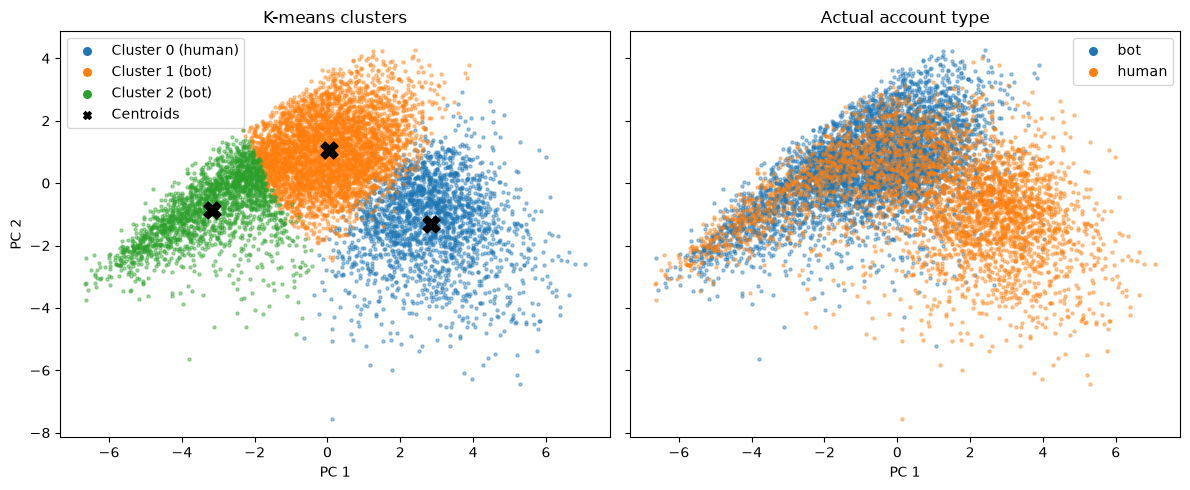

Variance explained by the 2 components: 0.39


In [14]:
from sklearn.decomposition import PCA

# Compress the 21 scaled features down to 2 so we can plot them
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_train_scaled)
centers_2d = pca.transform(kmeans.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

# Left: colored by k-means cluster
for c in sorted(train_df["cluster"].unique()):
    mask = (train_df["cluster"] == c).values
    axes[0].scatter(X_2d[mask, 0], X_2d[mask, 1], s=5, alpha=0.4,
                    label=f"Cluster {c} ({cluster_labels[c]})")
axes[0].scatter(centers_2d[:, 0], centers_2d[:, 1], c="black", marker="X", s=150, label="Centroids")
axes[0].set_title("K-means clusters")

# Right: colored by the real label
for lab in ["bot", "human"]:
    mask = (train_df["account_type"] == lab).values
    axes[1].scatter(X_2d[mask, 0], X_2d[mask, 1], s=5, alpha=0.4, label=lab)
axes[1].set_title("Actual account type")

for ax in axes:
    ax.set_xlabel("PC 1")
    leg = ax.legend()
    for h in leg.legend_handles:
        h.set_sizes([30])
        h.set_alpha(1)
axes[0].set_ylabel("PC 2")
plt.tight_layout()
plt.show()

print("Variance explained by the 2 components:", pca.explained_variance_ratio_.sum().round(2))

In [15]:
pd.DataFrame(pca.components_.T, index=X_train.columns, columns=["PC1", "PC2"]).round(2)

,PC1,PC2
followers_count,0.38,-0.11
friends_count,0.14,0.43
listed_count,0.36,-0.20
favourites_count,0.20,0.41
geo_enabled,0.18,0.05
verified,0.28,-0.29
statuses_count,0.36,0.26
is_translation_enabled,0.11,-0.15
profile_background_tile,0.14,-0.04
profile_use_background_image,-0.09,-0.02


### Visualizing the Clusters

The data has 21 features, so we used principal component analysis(PCA) to project it down to 2 dimensions for plotting. The two components explain 39% of the variance, so this is a rough view. Points that overlap here may be farther apart in the full feature space.

**What the axes mean.** 

PC1 measures how big and established an account is. Followers, listed count, statuses, verified, account age and follower-to-friend ratio all have positive weights, and default profile has a negative weight. Accounts on the right are large, older accounts with a lot of activity. Accounts on the left are newer and mostly empty. PC2 measures how an account uses Twitter. Friends count and favourites have the biggest positive weights, while follower-to-friend ratio and verified are negative. Accounts near the top follow and like a lot of other accounts. Accounts near the bottom have far more followers than people they follow, which is typical of public figures and news outlets.

**Where the clusters fall.** 

Cluster 0 (human) sits in the lower right, which is the established, verified accounts with large audiences. Cluster 1 (bot) sits in the middle and upper area, which is active accounts that follow and favorite a lot. Cluster 2 (bot) sits on the left, which is newer accounts with little activity and default profiles.

**Comparing to the real labels.** 

The human region in the lower right lines up well with cluster 0, and very few bots show up there. In the middle and left, humans are mixed in with the bots everywhere, and bots never form a clean region of their own. This matches the 1,655 humans that ended up in the two bot clusters. K-means can pick out famous accounts as human, but regular humans and bots look alike on these features, so they get grouped together.

### Baseline comparison

To check what the clusters are actually picking up, we compared the model to a simple rule: call every unverified account a bot and every verified account a human.

In [16]:
# Baseline: call every unverified account a bot
verified_rule = np.where(train_df["verified"], "human", "bot")
print(confusion_matrix(train_df["account_type"], verified_rule))
print(classification_report(train_df["account_type"], verified_rule))

[[4645    1]
 [1576 2056]]
              precision    recall  f1-score   support

         bot       0.75      1.00      0.85      4646
       human       1.00      0.57      0.72      3632

    accuracy                           0.81      8278
   macro avg       0.87      0.78      0.79      8278
weighted avg       0.86      0.81      0.80      8278



## Testing

The test set goes through the same `prepare_features` function with the training reference date, then gets scaled with the scaler fit on the training set. Each test account is assigned to its nearest training centroid and takes that cluster's label. Nothing is refit on the test data.

Prepare the test set

In [17]:
test_df = pd.read_csv('test_users_cleaned.csv')

X_test = prepare_features(test_df, ref_date)

# Make sure columns are in the same order the scaler and k-means saw during training
X_test = X_test[X_train.columns]

# Check for missing values (the scaler will error on NaN)
X_test.isnull().sum()[X_test.isnull().sum() > 0]

Series([], dtype: int64)

Predict and score

In [18]:
# transform only, do not fit. The scaler and k-means come from the training set
X_test_scaled = scaler.transform(X_test)

test_df["cluster"] = kmeans.predict(X_test_scaled)
test_df["predicted"] = test_df["cluster"].map(cluster_labels)

print(confusion_matrix(test_df["account_type"], test_df["predicted"]))
print(classification_report(test_df["account_type"], test_df["predicted"]))

[[628  12]
 [226 317]]
              precision    recall  f1-score   support

         bot       0.74      0.98      0.84       640
       human       0.96      0.58      0.73       543

    accuracy                           0.80      1183
   macro avg       0.85      0.78      0.78      1183
weighted avg       0.84      0.80      0.79      1183



In [19]:
pd.crosstab(test_df["cluster"], test_df["account_type"])

account_type,bot,human
cluster,,
0,12,317
1,440,152
2,188,74


In [20]:
verified_rule_test = np.where(test_df["verified"], "human", "bot")
print(confusion_matrix(test_df["account_type"], verified_rule_test))
print(classification_report(test_df["account_type"], verified_rule_test))

[[640   0]
 [217 326]]
              precision    recall  f1-score   support

         bot       0.75      1.00      0.86       640
       human       1.00      0.60      0.75       543

    accuracy                           0.82      1183
   macro avg       0.87      0.80      0.80      1183
weighted avg       0.86      0.82      0.81      1183



### Test results

The model gets 80% accuracy on the 1,183 test accounts. Always guessing bot would get 54% on the test set. That is slightly higher than the 78% on training and the 78.4% from cross-validation, so the model generalizes to new accounts and is not overfitting.

The pattern matches training. The model catches 98% of bots and misses only 12. Humans are still the weak spot, since only 58% are labeled correctly and 226 humans get called bots. When the model says human it is right 96% of the time.

The clusters also behave the same way on new data. Cluster 0 is 96% human, and clusters 1 and 2 are 74% and 72% bots, which is within a few points of the training split. The centroids found on the training set are picking up a real structure and not noise specific to those accounts.

The verified-only rule gets 82% on the test set, compared to 80% for k-means. None of the test bots are verified, so that rule makes no mistakes on bots, and it gets 326 humans right compared to 317 for k-means. The gap is the same size as on training.

## Conclusion

K-means with 3 clusters gets 80% accuracy on the test set (78% on training), which beats guessing bot every time (54% on test) and does much better than our first approach. That approach fit k-means only on human accounts and flagged anything far from every human cluster as a bot. It got 46% accuracy and caught only 12% of bots, because bots are not outliers in this data. They look like ordinary accounts, and the accounts that stand out are famous humans.

The model's main weakness is regular humans. It catches 98% of test bots but labels only 58% of test humans correctly. A simple rule that calls every unverified account a bot gets 82% on the test set, slightly better than k-means. Only 1 bot in the training set is verified and none in the test set are, so most of what the clusters pick up is verification status and the popularity features that go with it. Part of this comes from the dataset itself, since the human class has a lot of verified, well-known accounts.

To tell regular humans apart from bots, a future model would need either a supervised method trained on the labels, or features about behavior and tweet content that this dataset does not have.